# Brownfield land: checking the `hectares` field
**Author**:  Sian Wilson <br>
**Date**:  23rd November 2026 <br>
**Dataset Scope**: `brownfield-land` <br>
**Report Type**: Ad-hoc analysis <br>

## Purpose

For [digital-land/config#1938](https://github.com/digital-land/config/issues/1938) (Jira: [DLSD-2224](https://mhclgdigital.atlassian.net/browse/DLSD-2224)). A data user reported that some `hectares` values look like square metres, naming Milton Keynes and Cheshire West's `NOW/0043`. This notebook looks at how widespread that is and tests the limits proposed on the ticket.

## Summary

- 44 of 39,816 values are over 1,000 ha, and 39 of those are Milton Keynes.
- **Milton Keynes** has 46 values in square metres, all from one file collected 25 to 26 September 2025. The council has since renamed the column `SQM`, which we don't map, so we still publish the old values. We can fix this by retiring that file.
- **Other likely errors over 100 ha** are single values: Sandwell `7621`, Cheshire West `NOW/0043`, East Cambridgeshire `BLR3120`, Erewash `BLR133` and Thanet `171670`.
- **Maximums**: over 1,000 ha works as an error, once South Cambridgeshire has confirmed Northstowe (`17SC0009`, 1,380.9 ha). 100 to 1,000 ha should only be a warning, as it includes known large sites.
- **Minimums**: under 0.001 ha works as an error, but 102 of those 118 values are zeros, which may be better reported as missing. 0.001 to 0.01 ha should only be a warning, as many look like real small plots.
- **A limit won't catch everything.** Two Milton Keynes values are under 100 ha, and 34 Tamworth and 34 Wolverhampton values changed by ×10 but none is over 11 ha.
- `hectares` is a decimal, so limits belong in [`decimal.py`](https://github.com/digital-land/digital-land-python/blob/main/digital_land/datatype/decimal.py), not `integer.py`. They should apply to `hectares` only, as the code is shared by all decimal fields. Out-of-range values are blanked there, so a warning would need something new. It already has a default minimum of 0, which rejects negatives but not zeros.

In [1]:
import urllib.parse

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from matplotlib.ticker import FuncFormatter

pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.6g}")
plain = FuncFormatter(lambda x, _: f"{x:,.10g}")


def datasette_sql(db, sql):
    url = f"https://datasette.planning.data.gov.uk/{db}.json?" + urllib.parse.urlencode({"sql": sql, "_shape": "objects"})
    data = requests.get(url, timeout=60).json()
    if data.get("error") or data.get("truncated"):
        raise ValueError(data.get("error") or "result truncated")
    return pd.DataFrame(data["rows"])

## Data Import

The published dataset, plus every `hectares` fact on the platform, which includes earlier values for each entity.

In [2]:
files_url = "https://files.planning.data.gov.uk"
bl = pd.read_csv(f"{files_url}/dataset/brownfield-land.csv", dtype=str)
orgs = pd.read_csv(f"{files_url}/organisation-collection/dataset/organisation.csv", dtype=str)
facts = pd.read_csv("https://datasette.planning.data.gov.uk/brownfield-land/fact.csv?_stream=on&field=hectares&_labels=off")

bl["entity"] = bl["entity"].astype(int)
bl["ha"] = pd.to_numeric(bl["hectares"])
bl["dwellings"] = pd.to_numeric(bl["maximum-net-dwellings"], errors="coerce")
bl["org_name"] = bl["organisation-entity"].map(orgs.set_index("entity")["name"])

print(f"{len(bl):,} entities, {bl['ha'].notna().sum():,} with a hectares value")

40,228 entities, 39,816 with a hectares value


## Distribution

In [3]:
bl["ha"].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]).to_frame()

,ha
count,"39,816"
mean,22.7154
std,"2,177.91"
min,0
1%,0.01
5%,0.02
25%,0.08
50%,0.23
75%,0.64
95%,3.98


Log scales, as the values range from 0.00002 to 400,000. The lines are the limits proposed on the ticket. Zeros can't be shown on a log scale.

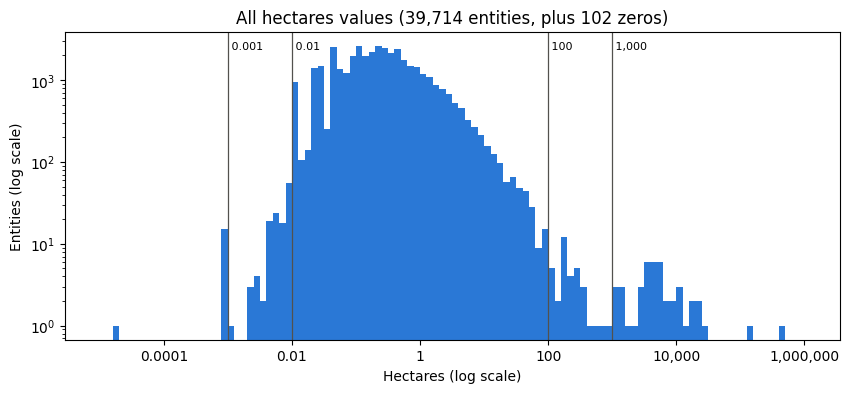

In [4]:
pos = bl.loc[bl["ha"] > 0, "ha"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(pos, bins=np.logspace(-5, 6, 111), color="#2a78d6", log=True)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(plain)
for x in (0.001, 0.01, 100, 1000):
    ax.axvline(x, color="#52514e", lw=0.9)
    ax.text(x, 0.97, f" {x:,}", transform=ax.get_xaxis_transform(), va="top", fontsize=8)
ax.set_title(f"All hectares values ({len(pos):,} entities, plus {(bl['ha'] == 0).sum()} zeros)")
ax.set_xlabel("Hectares (log scale)")
ax.set_ylabel("Entities (log scale)")
plt.show()

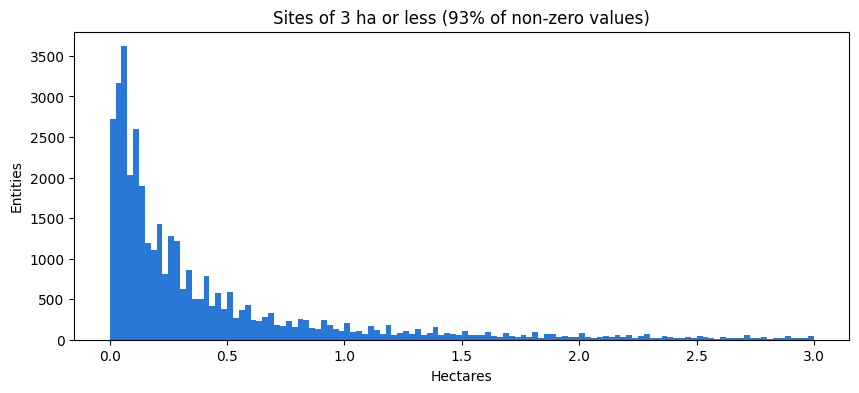

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(pos[pos <= 3], bins=np.arange(0, 3.001, 0.025), color="#2a78d6")
ax.set_title(f"Sites of 3 ha or less ({(pos <= 3).mean():.0%} of non-zero values)")
ax.set_xlabel("Hectares")
ax.set_ylabel("Entities")
plt.show()

## Extreme values

In [6]:
bands = {
    "0": bl["ha"] == 0,
    "> 0 and < 0.001": (bl["ha"] > 0) & (bl["ha"] < 0.001),
    "0.001 to < 0.01": (bl["ha"] >= 0.001) & (bl["ha"] < 0.01),
    "0.01 to 100": bl["ha"].between(0.01, 100),
    "> 100 to 1,000": (bl["ha"] > 100) & (bl["ha"] <= 1000),
    "> 1,000": bl["ha"] > 1000,
}
is_mk = bl["org_name"] == "Milton Keynes City Council"
pd.DataFrame({"entities": {k: m.sum() for k, m in bands.items()},
              "Milton Keynes": {k: (m & is_mk).sum() for k, m in bands.items()}})

,entities,Milton Keynes
0,102,0
> 0 and < 0.001,16,0
0.001 to < 0.01,127,0
0.01 to 100,39492,51
"> 100 to 1,000",35,5
"> 1,000",44,39


Values over 100 ha outside Milton Keynes. `earlier_values` are other values we have held for the same entity.

In [7]:
earlier = facts.merge(bl[["entity", "ha", "org_name"]], on="entity")
earlier = earlier[earlier["value"] != earlier["ha"]]
bl["earlier_values"] = bl["entity"].map(earlier.groupby("entity")["value"].apply(list))

(bl[(bl["ha"] > 100) & ~is_mk].sort_values("ha", ascending=False)
 [["entity", "org_name", "reference", "ha", "earlier_values", "dwellings", "site-address"]])

,entity,org_name,reference,ha,earlier_values,dwellings,site-address
40227,1745654,Sandwell Metropolitan Borough Council,7621,"400,013",[0.49],0,Langley Swimming Centre
34333,1739293,Cheshire West and Chester Council,NOW/0043,"30,189",[1.56],102,"Land adjacent Dane County, Manchester Road, No..."
30967,1735754,East Cambridgeshire District Council,BLR3120,"13,832",[1.41],6,Dimmocks Cote 46 Stretham Road Wicken Ely Camb...
24033,1727543,South Cambridgeshire District Council,17SC0009,"1,380.9",NaN,NaN,"Northstowe, Longstanton Road, Cambridgeshire"
36174,1741151,Erewash Borough Council,BLR133,"1,109",NaN,6,"The Needlemakers Arms, 12 Kensington Street, I..."
312,1700378,Peterborough City Council,PDL/0017/17,745.3,NaN,"2,349",Land To The West Of London Road Peterborough
35283,1740246,Thanet District Council,171670,507.04,NaN,1,Land Adjacent 89 St Johns Avenue RAMSGATE Kent
34454,1739414,Cherwell District Council,BLR 106,449.25,NaN,NaN,"Heyford Park, Camp Road, Upper Heyford, OX25 5HD"
14730,1716351,Thanet District Council,SP05,320,NaN,NaN,Former Airport site Manston
36238,1741215,Nuneaton and Bedworth Borough Council,BR025,302,NaN,142,"Camp Hill Phase 3, Nuneaton"


Many of these are real large sites, such as Manston airport and Waterbeach barracks. Some can't be right, such as 1,109 ha for a pub (Erewash) or 507 ha for one dwelling (Thanet). Sandwell `7621` isn't a unit error: the row's columns are shifted in the council's file, and 400,013 is an easting.

Northstowe `17SC0009` is unclear. It has no earlier value or dwellings to check against, and the related `17SC0009b` is 176.5 ha, so it isn't counted as wrong below.

## Small values

The non-zero values under 0.001 ha (10 m²):

In [8]:
small = bl[bands["> 0 and < 0.001"]].sort_values("ha")
print("Next smallest Barnet value:", bl.loc[(bl["org_name"] == "London Borough of Barnet") & (bl["ha"] >= 0.001), "ha"].min())
small[["entity", "org_name", "reference", "ha", "earlier_values", "dwellings", "site-address"]]

Next smallest Barnet value: 0.018


,entity,org_name,reference,ha,earlier_values,dwellings,site-address
23617,1727106,East Riding of Yorkshire Council,BF/127,1.7e-05,[0.32],10,"Land South of Wilson Street, Anlaby with Anlab..."
36845,1741823,London Borough of Barnet,21/3726/FUL,0.000894,NaN,260,Barnet House 1255 High Road London N20 0EJ
36849,1741827,London Borough of Barnet,24/2966/FUL,0.000894,NaN,113,Intec House 49 Moxon Street Barnet EN5 5TS
36867,1741845,London Borough of Barnet,21/1468/PNO,0.000894,NaN,25,17 Park Road Barnet EN5 5RY
36871,1741849,London Borough of Barnet,21/1809/PNO,0.000894,NaN,20,17 Park Road Barnet EN5 5RY
36869,1741847,London Borough of Barnet,21/6029/FUL,0.000895,NaN,23,11 Gruneisen Road London N3 1LS
36870,1741848,London Borough of Barnet,16/2351/FUL,0.000895,NaN,22,12 - 18 High Road London N2 9PJ
18510,1720870,London Borough of Barnet,H/01054/13,0.000896,"[12.99, 1.47]","1,090","West Hendon Estate, West Hendon, London, NW9"
30128,1734731,London Borough of Barnet,19/1346/FUL,0.000896,[0.14],20,Development Site North Of 215 At Former 217 To...
36843,1741821,London Borough of Barnet,20/0276/FUL,0.000896,NaN,343,Site Office Beaufort Park Aerodrome Road Londo...


In [9]:
def top_orgs(d):
    return ", ".join(f"{k} {v}" for k, v in d["org_name"].value_counts().head(3).items())


rows = []
for band in ("0", "> 0 and < 0.001", "0.001 to < 0.01"):
    d = bl[bands[band]]
    rows.append({"band": band, "entities": len(d), "with end-date": d["end-date"].notna().sum(),
                 "5+ dwellings": (d["dwellings"] >= 5).sum(),
                 "earlier non-zero value": d["earlier_values"].map(lambda v: isinstance(v, list) and any(x > 0 for x in v)).sum(),
                 "top organisations": top_orgs(d)})
decimals = bl["hectares"].dropna().str.partition(".")[2].str.len()
print(f"{(decimals > 2).mean():.1%} of values have more than 2 decimal places")
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(rows).set_index("band"))

13.5% of values have more than 2 decimal places


,entities,with end-date,5+ dwellings,earlier non-zero value,top organisations
band,,,,,
0,102,12,35,17,"London Borough of Hackney 18, London Borough of Croydon 18, Cherwell District Council 10"
> 0 and < 0.001,16,1,16,3,"London Borough of Barnet 15, East Riding of Yorkshire Council 1"
0.001 to < 0.01,127,24,9,10,"London Borough of Southwark 41, Thanet District Council 27, City of Wolverhampton Council 21"


Barnet's values are almost identical for very different sites, including a 1,090 home estate, so they can't be areas. The zeros look more like missing values than measurements, though some could be tiny sites rounded down.

Many of the 0.001 to 0.01 ha values look like real small plots or flats. [The guidance](https://www.gov.uk/government/publications/brownfield-land-registers-data-standard/publish-your-brownfield-land-data) asks for up to 2 decimal places, so 0.01 is the smallest non-zero value a council should submit. That supports 0.01 as the limit, but as a warning, as plenty of values use more places.

## Milton Keynes

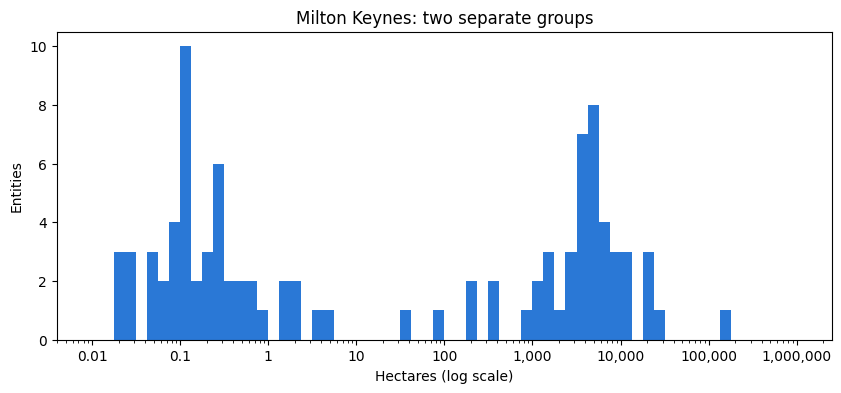

46 values over 10 ha; 45 have a non-zero earlier value
Median current value / earlier value: 10,013


In [10]:
mk = bl[is_mk]
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(mk["ha"], bins=np.logspace(-2, 6, 65), color="#2a78d6")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(plain)
ax.set_title("Milton Keynes: two separate groups")
ax.set_xlabel("Hectares (log scale)")
ax.set_ylabel("Entities")
plt.show()

high = mk[mk["ha"] > 10]
ratio = earlier[earlier["entity"].isin(high["entity"]) & (earlier["value"] > 0)].assign(ratio=lambda d: d["ha"] / d["value"])
print(f"{len(high)} values over 10 ha; {ratio['entity'].nunique()} have a non-zero earlier value")
print(f"Median current value / earlier value: {ratio['ratio'].median():,.0f}")

One hectare is 10,000 m², so these are square metres. Which file did they come from?

In [11]:
ids = ",".join(str(e) for e in high["entity"])
fr = datasette_sql("brownfield-land", f"SELECT field, resource, COUNT(DISTINCT entity) AS n FROM fact_resource WHERE entity IN ({ids}) AND field IN ('hectares', 'reference') GROUP BY 1, 2")
feed = datasette_sql("digital-land", """
    SELECT r.resource, r.start_date, r.end_date FROM endpoint e
    JOIN resource_endpoint re ON re.endpoint = e.endpoint
    JOIN resource r ON r.resource = re.resource
    WHERE e.endpoint_url LIKE 'https://miltonkeynes.statmap.co.uk/%TYPENAMES=statmap:brownfield_land&%'
    ORDER BY r.start_date""")
text = {r: requests.get(f"{files_url}/brownfield-land-collection/collection/resource/{r}", timeout=60).text for r in feed["resource"]}
feed["area column"] = ["SQM" if "<statmap:SQM>" in text[r] else "Hectares" if "<statmap:Hectares>" in text[r] else "" for r in feed["resource"]]
counts = fr.pivot(index="resource", columns="field", values="n")
feed["entities in file"] = feed["resource"].map(counts["reference"]).fillna(0).astype(int)
feed["given a hectares value"] = feed["resource"].map(counts["hectares"]).fillna(0).astype(int)

high_facts = facts[facts["entity"].isin(high["entity"]) & (facts["value"] > 10)]
src = datasette_sql("brownfield-land", f"SELECT fact, resource FROM fact_resource WHERE entity IN ({ids}) AND field = 'hectares'")
m2 = src[src["fact"].isin(high_facts["fact"])].groupby("resource")["fact"].nunique()
feed["values over 10"] = feed["resource"].map(m2).fillna(0).astype(int)
feed

,resource,start_date,end_date,area column,entities in file,given a hectares value,values over 10
0,b28aa0bea694eba659daeb08b9c8983b6a705cff001b7b...,2025-09-19,2025-09-21,Hectares,46,46,1
1,c45bff1c9a874de1d0279892c8785736421f5ca1bd17aa...,2025-09-22,2025-09-24,Hectares,46,46,1
2,64f77fcf29054cc0f4e11e7123d3c3b56a69eb450a985e...,2025-09-25,2025-09-26,Hectares,46,46,46
3,799e96aa24ba4381f23deb7343ff9d117337f973b83db5...,2025-09-27,2026-09-15,SQM,46,0,0
4,906f6c9095ccd0f646ac4a7c512e35be8b7fbd4368ba20...,2026-09-16,,SQM,46,0,0


All the square metre values come from one file (the single value over 10 in the two before it is `BR30`, a real 15.8 ha). From 27 September 2025 the column is called `SQM`, which isn't mapped, so no newer `hectares` value replaces them. `SQM` shouldn't be mapped to `Hectares`, as that would bring the problem back.

Retiring resource `64f77fcf...` in `old-resource.csv` should bring back the values from the file before it. This hasn't been tested. `BR99 B` is 0 in that file.

## Limits

How many values would each maximum flag?

In [12]:
likely_wrong = set(high["entity"])
for org, ref in [("Sandwell", "7621"), ("Cheshire West", "NOW/0043"), ("East Cambridgeshire", "BLR3120"), ("Erewash", "BLR133"), ("Thanet", "171670")]:
    found = bl[bl["org_name"].str.startswith(org, na=False) & (bl["reference"] == ref)]
    assert len(found) == 1
    likely_wrong.add(found["entity"].iloc[0])
wrong = bl["entity"].isin(likely_wrong)

pd.DataFrame([{"maximum ha": x, f"likely wrong, flagged (of {len(likely_wrong)})": (wrong & (bl["ha"] > x)).sum(),
               "other sites flagged": (~wrong & (bl["ha"] > x)).sum()} for x in (50, 100, 200, 500, 1000)]).set_index("maximum ha")

,"likely wrong, flagged (of 51)",other sites flagged
maximum ha,,
50,50,81
100,49,30
200,48,12
500,45,2
1000,43,1


Do the limits on the ticket hold up?

| Limit (ha) | Ticket | Entities | What we found |
|---|---|---|---|
| under 0.001 | error | 118 | Agree for the 16 non-zero values. Consider reporting the 102 zeros as missing. |
| 0.001 to < 0.01 | warning | 127 | Agree. Many look like real small sites. |
| > 100 to 1,000 | warning | 35 | Agree. 6 look wrong (5 Milton Keynes, 1 Thanet). The other 29 include known large sites, but weren't checked one by one. |
| > 1,000 | error | 44 | Agree, subject to Northstowe. The other 43 look wrong, and 39 of them are Milton Keynes. |

A limit only finds extreme values. Values that changed by a power of ten from an earlier value, allowing for rounding:

In [13]:
p = earlier[(earlier["value"] >= 0.02) & (earlier["ha"] >= 0.02)]
found = []
for factor in (10, 100, 1000, 10_000):
    hit = p[(p["ha"] / factor - p["value"]).abs() <= 0.006 + 0.02 * p["value"]]
    found.append(hit.assign(factor=factor))
found = pd.concat(found).drop_duplicates(["entity", "factor"])
jumps = found.groupby(["org_name", "factor"]).agg(entities=("entity", "nunique"), largest_ha=("ha", "max")).sort_values("entities", ascending=False)
print(f"Only {earlier['entity'].nunique():,} entities have a different earlier value to compare with")
jumps[jumps["entities"] >= 3]

Only 5,281 entities have a different earlier value to compare with


,,entities,largest_ha
org_name,factor,,
Milton Keynes City Council,10000,44,"157,945"
Tamworth Borough Council,10,34,10.5581
City of Wolverhampton Council,10,34,1.699
Wigan Metropolitan Borough Council,100,3,6.894
Stratford-on-Avon District Council,10,3,4.1


Tamworth and Wolverhampton are worth raising with the councils. An earlier value isn't always the right one, so this shows what to check, not what to correct.